In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

from sklearn.tree import plot_tree

In [6]:
df = pd.DataFrame({
    "StudyHours": [2, 8, 5, 1, 9, 7, 4, 6, 3, 10,
                   5, 2, 8, 9, 1, 7, 6, 4, 3, 10],
    "Attendance": [60, 95, 80, 50, 98, 90, 75, 85, 65, 99,
                   82, 55, 97, 96, 45, 88, 84, 70, 68, 100],
    "AssignmentScore": [50, 90, 70, 40, 95, 88, 65, 80, 55, 98,
                        72, 48, 92, 94, 35, 85, 78, 68, 60, 99],
    "Participation": [2, 5, 4, 1, 5, 5, 3, 4, 2, 5,
                      4, 2, 5, 5, 1, 4, 4, 3, 2, 5],
    "Pass": [0,1,1,0,1,1,1,1,0,1,
             1,0,1,1,0,1,1,1,0,1]
})
df.to_csv("../Datasets/student_performance1.csv", index=False)
df.shape

(20, 5)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   StudyHours       20 non-null     int64
 1   Attendance       20 non-null     int64
 2   AssignmentScore  20 non-null     int64
 3   Participation    20 non-null     int64
 4   Pass             20 non-null     int64
dtypes: int64(5)
memory usage: 932.0 bytes


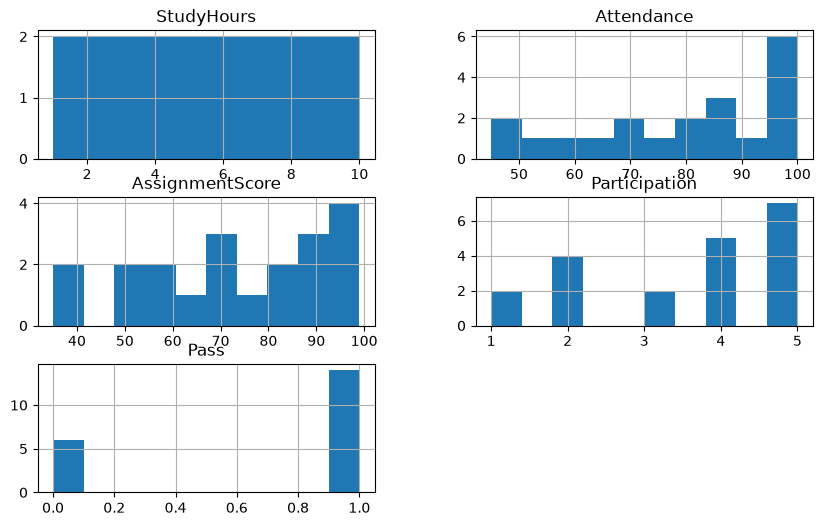

In [10]:
df.hist(figsize=(10,6))
plt.show()

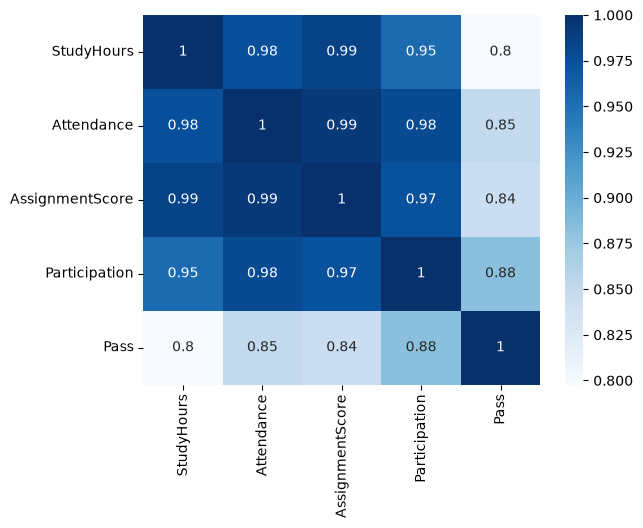

In [15]:
correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Blues"
)
plt.show()

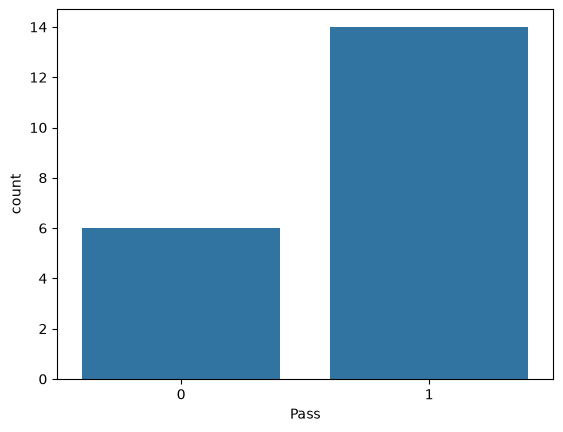

In [16]:
sns.countplot(x = "Pass", data=df)
plt.show()

In [18]:
df.isnull().sum()

StudyHours         0
Attendance         0
AssignmentScore    0
Participation      0
Pass               0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.dtypes

StudyHours         int64
Attendance         int64
AssignmentScore    int64
Participation      int64
Pass               int64
dtype: object

In [21]:
X = df.drop("Pass", axis=1)
y = df["Pass"]

In [22]:
print(X)

    StudyHours  Attendance  AssignmentScore  Participation
0            2          60               50              2
1            8          95               90              5
2            5          80               70              4
3            1          50               40              1
4            9          98               95              5
5            7          90               88              5
6            4          75               65              3
7            6          85               80              4
8            3          65               55              2
9           10          99               98              5
10           5          82               72              4
11           2          55               48              2
12           8          97               92              5
13           9          96               94              5
14           1          45               35              1
15           7          88               85             

In [23]:
print(y)

0     0
1     1
2     1
3     0
4     1
5     1
6     1
7     1
8     0
9     1
10    1
11    0
12    1
13    1
14    0
15    1
16    1
17    1
18    0
19    1
Name: Pass, dtype: int64


In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
print(X_train.shape)
print(y_train.shape)

(16, 4)
(16,)


In [31]:
pipeline = Pipeline(steps=[
    ("model", DecisionTreeClassifier(random_state=42))
]
)

In [32]:
pipeline.fit(X_train, y_train)
prediction = pipeline.predict(X_test)
print(prediction)

[1 0 0 0]


In [44]:
print("Accuricy:", accuracy_score(y_test, prediction))
print("Precision:", precision_score(y_test, prediction))
print("Recall:", recall_score (y_test, prediction))
print("F1 Score:", f1_score(y_test, prediction))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction))
print("\nClassification Report:")
print(classification_report(y_test, prediction))

Accuricy: 0.5
Precision: 1.0
Recall: 0.3333333333333333
F1 Score: 0.5

Confusion Matrix:
[[1 0]
 [2 1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.33      1.00      0.50         1
           1       1.00      0.33      0.50         3

    accuracy                           0.50         4
   macro avg       0.67      0.67      0.50         4
weighted avg       0.83      0.50      0.50         4



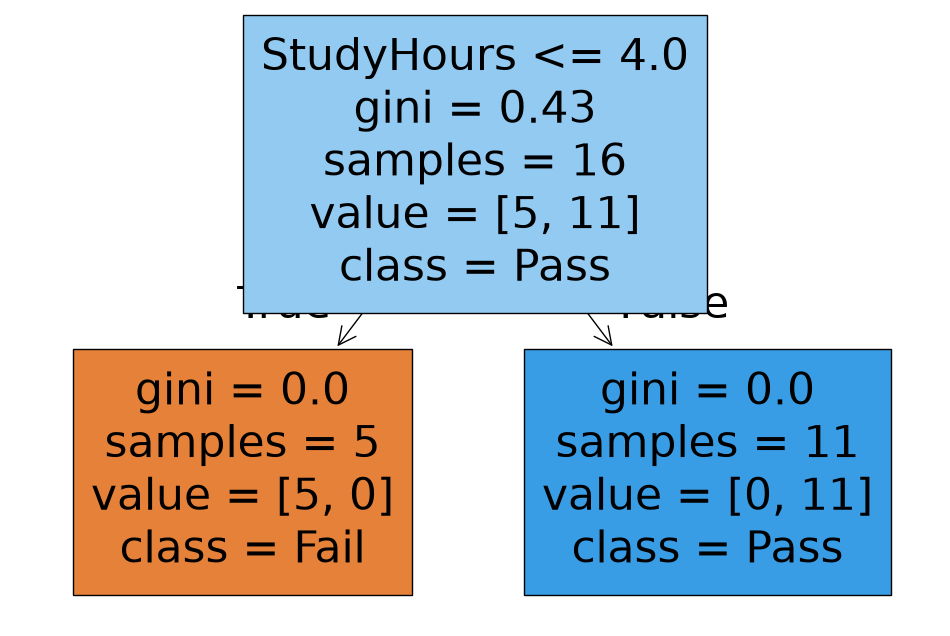

In [53]:
tree_model = pipeline.named_steps["model"]

plt.figure(figsize=(12,8))

plot_tree(tree_model,
         feature_names=X.columns,
         class_names=["Fail", "Pass"],
         filled=True)

plt.show()

In [65]:
train_score = pipeline.score(
    X_train, 
    y_train
)

test_score = pipeline.score(
    X_test,
    y_test
)

print("Train score:", train_score)
print("Test score:", test_score)

Train score: 1.0
Test score: 0.5


In [71]:
new_student = pd.DataFrame({
        "StudyHours":[3],
        "Attendance":[90],
        "AssignmentScore":[85],
        "Participation":[4]
})

new_prediction = pipeline.predict(new_student)
print(new_prediction)

[0]
